# Q1E | Train Polynomial Regression

> *E. Repeat everything from part D with polynomial regression and using SGD. Using validation loss, explore if your model overfits/underfits the data and report your findings. Ensure reproducibility by using a seed.*

Part E repeats part D, so part D is quoted too:

> *D. Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization: try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.*

---

#### IMPORTANT

This notebook uses only the `train` dataset, so no modeling decision is influenced by the test data (`data snooping`). Every model below is fit and scored on the training rows only.

# Answer Summary

**Setup:** every model is one pipeline scored on the same 20 folds as Q1D (4-fold cross validation over 5 seeds). The metric is rmse, in `Life Ladder` units. A model only counts as better when its rmse gain is more than 1 SE of the per-fold differences, and ties go to the simpler model. Every `random_state` is set to 42.

**Polynomial regression next to Q1D's linear model**

| Model | rmse | train rmse | Against Q1D's selected model |
|---|---|---|---|
| Dummy (always the mean) | 1.1287 | 1.1278 | worse |
| Linear, closed form | 0.5160 | 0.5121 | tie |
| Linear, Ridge SGD (Q1D's selected model) | 0.5164 | 0.5125 | |
| Degree 2, closed form | 0.4894 | 0.4727 | better |
| Degree 2, SGD, no penalty | 0.4889 | 0.4769 | better |
| Degree 2, Ridge SGD, `alpha=0.001`, `eta0=0.001` (selected) | 0.4889 | 0.4770 | better |

train rmse is the same model scored on its own training rows.

- **Degree 2 polynomial regression beats the linear model.** The selected model's rmse is 0.4889 against 0.5164, lower by 0.0275 with an SE of 0.0046. Closed form picks the degree: 0.5160, 0.4903 and 0.6169 at degrees 1, 2 and 3.
- **The polynomial terms are built on Q1D's hinge shapes, not in place of them.** Expanding the 8 attributes as stored scores 0.5092, and taking out either hinge shape is worse. Social support no longer needs its transform, and Generosity and Negative affect stay dropped.
- **SGD reaches the same fit as closed form** (0.4897 against 0.4894).
- **Regularization does not help.** Ridge at 0.001 and 0.01 and Elastic Net at 0.001 tie with plain SGD, and the other six settings are worse. A larger penalty underfits: at `alpha=0.1` rmse rises to 0.4937 for Ridge, 0.5041 for Elastic Net and 0.5443 for Lasso, which sets 34 of the 44 coefficients to exactly 0.
- **The stopping tolerance matters more than the learning rate.** With `tol=1e-5`, `eta0` 0.001 and 0.01 tie (0.4889 and 0.4897), 0.0001 is worse (0.4956) and 0.1 fails on every fold. With scikit-learn's default tolerance SGD stops too early at every rate (0.4997 at 0.001 and 0.6986 at 0.0001), so every SGD model here uses `tol=1e-5`.
- **The selected model is Ridge at `alpha=0.001`,** the smallest penalty among the tied settings. The question asks for a regularized model, and this one scores the same as plain SGD and closed form. Fit on the 1,374 complete training rows it stops after 168 epochs with a training rmse of 0.4789.
- **Overfitting and underfitting, read from validation loss:**
  - **The selected model** does not underfit and overfits only slightly. Its validation rmse is lowest at epoch 173 (0.4879) and ends at 0.4891 after 2000 epochs, with training rmse at 0.4733.
  - **Degree 1 underfits.** Both lines go flat at once and stay high (0.5163 and 0.5201).
  - **Degree 3 overfits.** With more epochs its training rmse falls to 0.4388 while its validation rmse climbs from 0.4830 to 0.4913, and fit to the end with closed form it scores 0.6169.
  - **A strong penalty or an early stop underfits:** training and validation rmse rise together.

**Carried forward:** the fitted pipeline, saved as `polynomial_regression.joblib`. It takes the 8 attributes as they are stored, and its cross validated rmse of 0.4889 is the estimate for rows it has not seen.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import PowerTransformer

from Q1.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	SCORING,
	FEATURES,
	PIPELINES,
)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Setup

## Rows and Folds

In [3]:
ATTRIBUTES = [column["col"] for key, column in COLUMNS.items() if key != "LL"]

X = train_df[ATTRIBUTES]
y = train_df[TARGET]

# rows with no missing attribute: the only rows used for training and for validation
complete = X.notna().all(axis=1)
X_complete = X[complete]
y_complete = y[complete]

FOLDS = PIPELINES.make_folds(X, seeds=SEEDS)

print(f"rows: {len(X)} | complete: {complete.sum()} | incomplete: {(~complete).sum()}")
print(f"folds: {len(FOLDS)}")

rows: 1559 | complete: 1374 | incomplete: 185
folds: 20


## Feature Columns

In [4]:
GDP = COLUMNS["LGDP"]["col"]
SOCIAL = COLUMNS["SS"]["col"]
LIFE_EXP = COLUMNS["HLEAB"]["col"]
GENEROSITY = COLUMNS["G"]["col"]
NEG_AFFECT = COLUMNS["NA"]["col"]

# the shapes Q1D selected, with its thresholds
#   HighHinge:                [max(0, x - t)]
#   HighHinge(keep_raw=True): [x, max(0, x - t)]
#   PowerTransformer:         [YJ(x)], Yeo-Johnson with its power fit on the training rows, then standardized
SHAPES = {
	GDP: {"shape": [FEATURES.HighHinge(t=10.3, keep_raw=True), FEATURES.HighHinge(t=10.9)]},
	LIFE_EXP: {"shape": FEATURES.HighHinge(t=57.5)},
	SOCIAL: {"yeo-johnson": PowerTransformer(method="yeo-johnson")},
}

# Q1D's selected feature set: 8 feature columns from 6 of the 8 attributes
Q1D_FEATURES = {GDP: "shape", LIFE_EXP: "shape", SOCIAL: "yeo-johnson", GENEROSITY: "drop", NEG_AFFECT: "drop"}


def build(choice, estimator, *, degree=1, scale=False):
	"""One pipeline for a feature choice, a degree and a model: features > (polynomial terms) > (scaler) > model.

	Args:
		choice: What each attribute contributes: "raw", "drop" or the name of one of its SHAPES. Attributes left
			out are "raw", so {} is the 8 attributes as they are stored.
		estimator: Final model.
		degree: Degree of the polynomial terms built from the feature columns. 1 adds nothing.
		scale: Standardize the columns before the model and, with degree above 1, also before the polynomial
			terms are built.
	"""
	return PIPELINES.attribute_pipeline(
		estimator, attributes=ATTRIBUTES, shapes=SHAPES, choice=choice, degree=degree, scale=scale,
	)


feature_columns = build(Q1D_FEATURES, LinearRegression())["features"].fit(X_complete).get_feature_names_out()
display(pd.Series(feature_columns, index=pd.RangeIndex(1, len(feature_columns) + 1), name="Q1D's feature columns").to_frame())

# what each degree builds from those 8 columns. A column times its own hinge is an exact combination of two
# other columns (x · hinge = hinge² + t · hinge), so some columns add nothing new: "independent" leaves them out
column_counts = {}
for degree in [1, 2, 3]:
	columns = build(Q1D_FEATURES, LinearRegression(), degree=degree, scale=True)[:-1].fit_transform(X_complete)
	column_counts[degree] = {"columns": columns.shape[1], "independent": np.linalg.matrix_rank(columns)}

display(pd.DataFrame(column_counts).T.rename_axis("degree"))

,Q1D's feature columns
1,Log GDP per capita
2,Log GDP per capita__hinge_10.3
3,Log GDP per capita__hinge_10.9
4,Social support
5,Healthy life expectancy at birth__hinge_57.5
6,Freedom to make life choices
7,Perceptions of corruption
8,Positive affect


,columns,independent
degree,,
1,8,8
2,44,41
3,164,139


## Scoring

In [5]:
RESULTS = {}


def score(name, pipeline):
	"""Score a pipeline on FOLDS, on the complete rows, and keep its per-fold scores in RESULTS under name.

	Args:
		name: Row label of the model in every table.
		pipeline: Model or pipeline to score.
	"""
	RESULTS[name] = PIPELINES.evaluate_pipeline(pipeline, X=X_complete, y=y_complete, folds=FOLDS, return_train_score=True)


def table(names, *, baseline, holm=False):
	"""Results table of the named models, with the noise threshold against baseline.

	Args:
		names: Models to show, each already scored with score.
		baseline: Name of the model the rmse difference is measured against. It must be in names.
		holm: Add the Holm adjusted p and the "significant" verdict.
	"""
	return SCORING.results_df({name: RESULTS[name] for name in names}, baseline=baseline, holm=holm, decimals=4)


def fold_range(names):
	"""The spread of the named models over the folds, for a model that fails on some of them.

	Args:
		names: Models to show, each already scored with score. "Dummy" must be scored too.

	Returns:
		One row per model: its mean validation and training rmse, its lowest, median and highest fold rmse, and
		the number of folds where its rmse is above the Dummy's on the same fold. The rmse columns are text, so
		a run in the billions does not push the whole table into scientific notation.
	"""
	rows = {}
	for name in names:
		rmse = RESULTS[name]["rmse"]
		values = {
			"rmse mean": rmse.mean(),
			"train rmse mean": RESULTS[name]["train_rmse"].mean(),
			"lowest fold": rmse.min(),
			"median fold": np.median(rmse),
			"highest fold": rmse.max(),
		}
		rows[name] = {column: f"{value:.4f}" if value < 1000 else f"{value:.2e}" for column, value in values.items()}
		rows[name]["folds above Dummy"] = int((rmse > RESULTS["Dummy"]["rmse"]).sum())
	return pd.DataFrame.from_dict(rows, orient="index")

# Method

Every model is one `Pipeline` from `build(choice, estimator, degree=)`: features, (polynomial terms), (scaler), model. `choice` sets each attribute to `"raw"`, `"drop"` or the name of one of its shapes in `SHAPES`, and every step is fit inside each training fold.

- **Polynomial regression:** linear regression on extra columns. At degree 2 the pipeline adds each feature column squared and each pair of feature columns multiplied, and at degree 3 every product of three. Degree 1 adds nothing.
- **What is expanded:** the starting point is Q1D's selected feature columns (`Q1D_FEATURES`), so the degree 1 model is Q1D's model and a higher degree changes only the polynomial terms. What Is Expanded tests that choice. The thresholds are Q1D's, found on all the training rows, so a shape's gain is slightly optimistic.
- **Folds:** the same 20 folds as Q1D (4-fold cross validation over the 5 `SEEDS`), built once and used by every model, so a polynomial model can be compared with Q1D's models fold by fold.
- **Rows:** complete rows only. Q1D found no gain from imputing the 185 incomplete rows.
- **Metric:** rmse. It is in `Life Ladder` units, counts large misses more than small ones, and is the squared error a linear regression minimizes. mae and r2 are reported next to it, and `train rmse mean` is the same model scored on its own training rows.
- **Scaling:** SGD models standardize the feature columns before the polynomial terms are built, and standardize the polynomial columns again before the model. Closed form uses no scaler.
- **SGD stopping:** every SGD model fit for this notebook stops at `tol=1e-5`, tighter than scikit-learn's default of 0.001. Stopping Tolerance shows why. `Linear, Ridge SGD` keeps the default, as in Q1D.
- **Redundant columns:** some polynomial columns are exact combinations of others (the table in Feature Columns counts them). They do not change a prediction, but they leave closed form more than one set of coefficients that fits equally well.
- **Seed:** the folds come from `SEEDS`, and every `random_state` in a pipeline is set to 42, so a rerun gives the same numbers.

**Noise threshold (Δrmse vs the baseline)**

- Δ is the mean of the per-fold rmse differences d (model minus baseline). Negative means lower error than the baseline.
- The folds share most of their training rows, so the SE of Δ uses the Nadeau and Bengio correction: `SE = sqrt(var(d) · (1/folds + n_test/n_train))`. `Δ / SE` is the corrected t statistic and `p` its one-sided p-value.
- `verdict`:
  - **within noise:** Δ is within 1 SE of 0.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE.
  - **significant** (tables with `p (Holm)` only): the Holm adjusted p is below 0.05, adjusted over that table's rows.
- **A model that fails on some folds** (an rmse above the Dummy's) gets no verdict. Those folds set both its mean and its SE, so `fold_range` shows its lowest, median and highest fold in their place.

**Decisions**

- **Ties go to the simpler model.** A row that adds something (columns, a penalty) is kept only if it is **candidate** or **significant**. A row that removes something is kept unless it is **worse**.
- **Among tied settings the smaller one wins:** the smaller penalty, as the model closest to no penalty, and the smaller learning rate, as the one furthest from the rates that fail.
- **The degree is chosen with closed form,** which fits each degree to the end, so the choice does not depend on where SGD stops.
- **Each section's choice is the next section's baseline.**

# Baselines

A model that always predicts the mean `Life Ladder`, then Q1D's two models scored again on the same folds. They are the rows every polynomial model is compared with.

## Dummy Regressor

In [6]:
score("Dummy", DummyRegressor(strategy="mean"))
display(table(["Dummy"], baseline="Dummy"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Dummy,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Dummy,1.1287,0.0294,1.1278,0.9357,0.0263,-0.0044,0.0056,0.0,NaN,NaN,NaN,baseline,20


## Q1D's Linear Models

Both are degree 1 on `Q1D_FEATURES`: closed form `LinearRegression`, and Q1D's selected model, Ridge SGD at `alpha=0.001` and `eta0=0.01` with scikit-learn's default stopping rule.

In [7]:
score("Linear, closed form", build(Q1D_FEATURES, LinearRegression()))
score("Linear, Ridge SGD", build(Q1D_FEATURES, SGDRegressor(penalty="l2", alpha=0.001, eta0=0.01), scale=True))

display(table(["Dummy", "Linear, closed form", "Linear, Ridge SGD"], baseline="Linear, closed form"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Linear, closed form",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Linear, closed form",0.5160,0.0224,0.5121,0.3947,0.0161,0.7896,0.0181,0.0000,NaN,NaN,NaN,baseline,20
"Linear, Ridge SGD",0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0004,0.0006,0.6557,0.7401,within noise,20
Dummy,1.1287,0.0294,1.1278,0.9357,0.0263,-0.0044,0.0056,0.6127,0.0196,31.2586,1.0000,worse,20


## Results

- **Q1D's two models score here what they scored in Q1D.** `Linear, closed form` has an rmse of 0.5160 and `Linear, Ridge SGD` 0.5164, so the folds and the pipeline are the same. The two are a tie: a change of 0.0004 against an SE of 0.0006.
- **Neither overfits, and both are far below the Dummy** (1.1287). Training rmse (0.5121 and 0.5125) sits just below validation rmse.

**Carry forward**

- **`Linear, closed form`** (rmse 0.5160) as the degree 1 model the Degree section starts from.
- **`Linear, Ridge SGD`** (rmse 0.5164), Q1D's selected model, as the row the selected polynomial model is compared with.

# Polynomial Features

Which degree, and which columns are expanded. Every model in this section is closed form `LinearRegression`, which has no learning rate or seed to add noise to the comparison.

## Degree

Q1D's feature columns expanded to degree 2 and to degree 3. Degree 1 is `Linear, closed form`, the same columns with no polynomial terms.

In [8]:
DEGREES = {f"Degree {degree}": degree for degree in [2, 3]}

for name, degree in DEGREES.items():
	score(name, build(Q1D_FEATURES, LinearRegression(), degree=degree))

# every degree over the folds: a degree with a fold above the Dummy's rmse gets no verdict below
display(fold_range(["Linear, closed form", *DEGREES]))

,rmse mean,train rmse mean,lowest fold,median fold,highest fold,folds above Dummy
"Linear, closed form",0.5160,0.5121,0.4721,0.5133,0.5574,0
Degree 2,0.4903,0.4741,0.4409,0.4903,0.5372,0
Degree 3,0.6169,0.4253,0.4669,0.5331,1.6697,1


In [9]:
display(table(["Linear, closed form", "Degree 2"], baseline="Linear, closed form"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Linear, closed form",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Degree 2,0.4903,0.0238,0.4741,0.3777,0.0184,0.8099,0.0191,-0.0258,0.0061,-4.2147,0.0002,candidate,20
"Linear, closed form",0.5160,0.0224,0.5121,0.3947,0.0161,0.7896,0.0181,0.0000,NaN,NaN,NaN,baseline,20


### Results

- **Degree 2 is better than the linear model.** rmse falls from 0.5160 to 0.4903, a change of -0.0258 against an SE of 0.0061 (Δ / SE -4.21), and r2 rises from 0.7896 to 0.8099.
- **Next to it, degree 1 underfits.** Its training and validation rmse are close together (0.5121 and 0.5160) and both are higher than degree 2's (0.4741 and 0.4903).
- **Degree 3 overfits.** Its 164 columns bring training rmse down to 0.4253 while validation rmse rises to 0.6169. Its median fold (0.5331) is above degree 2's (0.4903), and on one fold (1.6697) it is worse than the Dummy.

**Carry forward**

- **`Degree 2`** (rmse 0.4903) as the baseline for What Is Expanded.

**Ignore**

- **Degree 3,** as a closed form model. The Overfitting and Underfitting section looks at it again with SGD.

## What Is Expanded

Whether the degree 2 terms should be built from Q1D's feature columns or from something simpler.

### One Shape Taken Back Out

Each row puts one of Q1D's three shaped attributes back to its stored column before the expansion. A shape earns its place if taking it out is **worse**.

In [10]:
WITHOUT_ONE = {
	f"{SHORT_NAMES[attribute]} as stored": {**Q1D_FEATURES, attribute: "raw"}
	for attribute in SHAPES
}

for name, choice in WITHOUT_ONE.items():
	score(name, build(choice, LinearRegression(), degree=2))

display(table(["Degree 2", *WITHOUT_ONE], baseline="Degree 2"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Degree 2,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Social as stored,0.4894,0.0236,0.4727,0.3766,0.0180,0.8105,0.0193,-0.0008,0.0013,-0.6252,0.2696,within noise,20
Degree 2,0.4903,0.0238,0.4741,0.3777,0.0184,0.8099,0.0191,0.0000,NaN,NaN,NaN,baseline,20
GDP as stored,0.5001,0.0224,0.4876,0.3847,0.0168,0.8023,0.0180,0.0098,0.0031,3.1678,0.9975,worse,20
Life exp as stored,0.5031,0.0201,0.4848,0.3896,0.0166,0.8000,0.0165,0.0128,0.0042,3.0576,0.9968,worse,20


### Other Column Sets

Two larger changes, against the model the table above leaves standing, `Social as stored`:

- **8 attributes as stored:** no shapes and no drops, so the polynomial terms do all the work.
- **Generosity + Neg affect put back:** Q1D's two drops undone.

In [11]:
# the choice left standing above: Social support back to its stored column
STANDING = WITHOUT_ONE["Social as stored"]

OTHER_SETS = {
	"8 attributes as stored": {},
	"Generosity + Neg affect put back": {**STANDING, GENEROSITY: "raw", NEG_AFFECT: "raw"},
}

for name, choice in OTHER_SETS.items():
	score(name, build(choice, LinearRegression(), degree=2))

# the columns each choice expands to at degree 2
column_counts = {}
for name, choice in {"Social as stored": STANDING, **OTHER_SETS}.items():
	columns = build(choice, LinearRegression(), degree=2, scale=True)[:-1].fit_transform(X_complete)
	column_counts[name] = {"columns": columns.shape[1], "independent": np.linalg.matrix_rank(columns)}

display(pd.DataFrame(column_counts).T)
display(table(["Social as stored", *OTHER_SETS], baseline="Social as stored"))

,columns,independent
Social as stored,44,41
8 attributes as stored,44,44
Generosity + Neg affect put back,65,62


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Social as stored,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Social as stored,0.4894,0.0236,0.4727,0.3766,0.0180,0.8105,0.0193,0.0000,NaN,NaN,NaN,baseline,20
Generosity + Neg affect put back,0.4932,0.0254,0.4649,0.3793,0.0194,0.8075,0.0213,0.0038,0.0041,0.9282,0.8175,within noise,20
8 attributes as stored,0.5092,0.0204,0.4860,0.3938,0.0147,0.7951,0.0164,0.0198,0.0056,3.5289,0.9989,worse,20


### Results

- **Social support does not need its transform at degree 2.** With its stored column in place of Yeo-Johnson, rmse is 0.4894 against 0.4903, within noise (-0.0008 against an SE of 0.0013). The stored column is the simpler form, so it is kept.
- **The two hinge shapes still earn their place.** Taking out Log GDP's hinges (0.5001) or Healthy life expectancy's hinge (0.5031) is worse, each by about 3 SE (Δ / SE 3.17 and 3.06).
- **Polynomial terms do not replace the shapes.** The 8 attributes as stored expand to the same number of columns (44) and score 0.5092, worse by 0.0198 against an SE of 0.0056.
- **Generosity and Negative affect stay out.** Putting them back takes the expansion from 44 to 65 columns and lowers training rmse from 0.4727 to 0.4649, but validation rmse goes up to 0.4932 (within noise). The extra columns fit the training rows more closely without predicting new rows better.

**Carry forward**

- **`Social as stored`** (rmse 0.4894) as the feature set for every model below: Log GDP's two hinges, Healthy life expectancy's hinge, and Social support, Freedom, Corruption and Positive affect as they are stored. At degree 2 that is 44 columns, 41 of them independent.

**Ignore**

- **Yeo-Johnson for Social support, the 8 attributes as stored, and putting Generosity and Negative affect back.**

# SGD

The same feature set and degree fit by stochastic gradient descent: compared with closed form, then the learning rate and the stopping tolerance.

In [12]:
# the feature set carried forward from What Is Expanded, and the degree carried forward from Degree
FEATURE_CHOICE = {GDP: "shape", LIFE_EXP: "shape", SOCIAL: "raw", GENEROSITY: "drop", NEG_AFFECT: "drop"}
DEGREE = 2
assert FEATURE_CHOICE == STANDING

# the closed form model on that feature set, under the name used from here on (nothing is scored again)
RESULTS["Closed form, degree 2"] = RESULTS["Social as stored"]

# SGD stops when the training loss has improved by less than TOL for 5 epochs in a row. scikit-learn's default
# is 0.001. MAX_ITER is only a safety limit on the epochs
TOL = 1e-5
MAX_ITER = 100_000


def sgd(**params):
	"""SGDRegressor with this notebook's stopping rule, and no penalty unless one is passed.

	Args:
		params: SGDRegressor parameters that differ from that (ex eta0, penalty, alpha).
	"""
	return SGDRegressor(**{"penalty": None, "tol": TOL, "max_iter": MAX_ITER, **params})


def epochs_run(estimator):
	"""Epochs an SGD model runs before it stops, fit once on all the complete rows.

	Args:
		estimator: SGD model, fit on FEATURE_CHOICE at DEGREE.
	"""
	fitted = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, estimator, degree=DEGREE, scale=True)).fit(X_complete, y_complete)
	return fitted["model"].n_iter_

## SGD vs Closed Form

`SGDRegressor` with no penalty and scikit-learn's default learning rate (`eta0=0.01`). It reaches its coefficients through repeated small steps, where closed form solves for them directly.

In [13]:
score("SGD", build(FEATURE_CHOICE, sgd(), degree=DEGREE, scale=True))

print(f"SGD epochs run: {epochs_run(sgd())}")
display(table(["Closed form, degree 2", "SGD"], baseline="Closed form, degree 2"))

SGD epochs run: 31


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, degree 2",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Closed form, degree 2",0.4894,0.0236,0.4727,0.3766,0.0180,0.8105,0.0193,0.0000,NaN,NaN,NaN,baseline,20
SGD,0.4897,0.0227,0.4762,0.3758,0.0166,0.8103,0.0188,0.0003,0.0022,0.1297,0.5509,within noise,20


### Results

- **SGD reaches the same fit as closed form.** Its rmse is 0.4897 against 0.4894, a change of 0.0003 against an SE of 0.0022, after 31 epochs on all the complete rows.
- **It stops just short on the training rows.** Its training rmse is 0.4762 against 0.4727 for closed form, which solves for the lowest training error these columns allow.

**Carry forward**

- **`SGD`** (rmse 0.4897) as the baseline for the learning rate. Closed form stays the simpler model with the same score.

## Learning Rate

`eta0` is the initial learning rate, the size of the first steps. Each row changes only `eta0`. `SGD` already uses 0.01, so it is the baseline and the 0.01 row.

In [14]:
ETA0S = {f"SGD, eta0={eta0}": eta0 for eta0 in LEARNING_RATES if eta0 != 0.01}

for name, eta0 in ETA0S.items():
	score(name, build(FEATURE_CHOICE, sgd(eta0=eta0), degree=DEGREE, scale=True))

# a rate with a fold above the Dummy's rmse failed: it is shown on its own and gets no verdict
failed = [name for name in ETA0S if (RESULTS[name]["rmse"] > RESULTS["Dummy"]["rmse"]).any()]
stable = ["SGD", *[name for name in ETA0S if name not in failed]]

display(fold_range(failed))
display(table(stable, baseline="SGD"))

,rmse mean,train rmse mean,lowest fold,median fold,highest fold,folds above Dummy
"SGD, eta0=0.1",2.95e+11,2.87e+11,4.07e+10,2.50e+11,1.13e+12,20


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.001",0.4889,0.0221,0.4769,0.3720,0.0156,0.8110,0.0179,-0.0008,0.0029,-0.2781,0.3920,within noise,20
SGD,0.4897,0.0227,0.4762,0.3758,0.0166,0.8103,0.0188,0.0000,NaN,NaN,NaN,baseline,20
"SGD, eta0=0.0001",0.4956,0.0230,0.4867,0.3760,0.0162,0.8058,0.0182,0.0059,0.0042,1.4169,0.9136,worse,20


The same rows against the lowest one, so the choice between the rates that work has its own verdict. Then the epochs each rate runs before it stops.

In [15]:
display(table(stable, baseline="SGD, eta0=0.001"))

display(
	pd.Series({eta0: epochs_run(sgd(eta0=eta0)) for eta0 in LEARNING_RATES})
	.rename_axis("eta0").to_frame("epochs run")
)

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.001",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.001",0.4889,0.0221,0.4769,0.3720,0.0156,0.8110,0.0179,0.0000,NaN,NaN,NaN,baseline,20
SGD,0.4897,0.0227,0.4762,0.3758,0.0166,0.8103,0.0188,0.0008,0.0029,0.2781,0.6080,within noise,20
"SGD, eta0=0.0001",0.4956,0.0230,0.4867,0.3760,0.0162,0.8058,0.0182,0.0067,0.0022,3.0098,0.9964,worse,20


,epochs run
eta0,
0.0001,896
0.0010,168
0.0100,31
0.1000,13


### Results

- **0.1 fails.** Its rmse is above the Dummy's on all 20 folds, with a median fold of 2.50e+11: the steps are too large, and the coefficients grow instead of settling.
- **0.001 and 0.01 tie.** They score 0.4889 and 0.4897, a difference of 0.0008 against an SE of 0.0029. 0.001 takes 168 epochs on all the complete rows where 0.01 takes 31.
- **0.0001 is worse.** Against 0.001 its rmse is higher by 0.0067 (SE 0.0022), although it runs 896 epochs. Its training rmse is higher too (0.4867 against 0.4769), so it has fit less by the time it stops.

**Carry forward**

- **`eta0=0.001`** (rmse 0.4889). It is the smaller of the two tied rates, one more step away from the rate that fails.

**Ignore**

- **0.0001 and 0.1.**

## Stopping Tolerance

The same four learning rates with scikit-learn's default stopping rule (`tol=0.001`, at most 1,000 epochs), which is the rule Q1D's models used. Each row is compared with `SGD, eta0=0.001`, the same model stopped at `tol=1e-5`.

In [16]:
DEFAULT_TOL = {f"eta0={eta0}, default tol": SGDRegressor(penalty=None, eta0=eta0) for eta0 in LEARNING_RATES}

for name, estimator in DEFAULT_TOL.items():
	score(name, build(FEATURE_CHOICE, estimator, degree=DEGREE, scale=True))

failed = [name for name in DEFAULT_TOL if (RESULTS[name]["rmse"] > RESULTS["Dummy"]["rmse"]).any()]
stable = [name for name in DEFAULT_TOL if name not in failed]

display(fold_range(failed))
display(table(["SGD, eta0=0.001", *stable], baseline="SGD, eta0=0.001"))

display(
	pd.Series({name: epochs_run(estimator) for name, estimator in DEFAULT_TOL.items()}).to_frame("epochs run")
)

,rmse mean,train rmse mean,lowest fold,median fold,highest fold,folds above Dummy
"eta0=0.1, default tol",2.95e+11,2.87e+11,4.07e+10,2.50e+11,1.13e+12,20


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.001",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.001",0.4889,0.0221,0.4769,0.3720,0.0156,0.8110,0.0179,0.0000,NaN,NaN,NaN,baseline,20
"eta0=0.01, default tol",0.4922,0.0219,0.4787,0.3757,0.0149,0.8085,0.0176,0.0033,0.0029,1.1245,0.8626,worse,20
"eta0=0.001, default tol",0.4997,0.0230,0.4911,0.3801,0.0162,0.8026,0.0184,0.0108,0.0029,3.6923,0.9992,worse,20
"eta0=0.0001, default tol",0.6986,0.0228,0.6942,0.5817,0.0218,0.6143,0.0289,0.2097,0.0119,17.6846,1.0000,worse,20


,epochs run
"eta0=0.0001, default tol",372
"eta0=0.001, default tol",37
"eta0=0.01, default tol",10
"eta0=0.1, default tol",13


### Results

- **The default tolerance stops SGD too early at every learning rate.** All three rates that work are worse than `SGD, eta0=0.001`: 0.4922 at 0.01, 0.4997 at 0.001 and 0.6986 at 0.0001.
- **The cost is underfitting, and it grows as the rate shrinks.** At 0.0001 the default rule stops after 372 epochs with training and validation rmse both high (0.6942 and 0.6986), where `tol=1e-5` runs 896 epochs and reaches a training rmse of 0.4867. At 0.001 it stops after 37 epochs (training rmse 0.4911) against 168 (0.4769). The rates can fit the data: they were stopped while still improving.
- **0.1 fails under either rule,** and no fit comes near a limit: the longest one on all the complete rows runs 896 epochs.

**Carry forward**

- **`tol=1e-5`** for every SGD model below, and **`SGD, eta0=0.001`** (rmse 0.4889) as the baseline for the penalties.

# Regularization

A penalty adds the size of the coefficients to the loss, which pulls them toward 0. `alpha` sets its strength.

- **Ridge** (`l2`): the sum of the squared coefficients.
- **Lasso** (`l1`): the sum of their absolute values, which can set a coefficient to exactly 0.
- **Elastic Net:** a mix of the two, at scikit-learn's default `l1_ratio=0.15`.

Each row changes only the penalty and its `alpha`, at the three values in `ALPHAS`. The baseline is `SGD, eta0=0.001`, the same model with no penalty.

In [17]:
# the learning rate carried forward from the SGD section
ETA0 = 0.001

PENALTIES = {"Ridge": "l2", "Lasso": "l1", "Elastic Net": "elasticnet"}

PENALIZED = {
	f"{name}, alpha={alpha}": sgd(penalty=penalty, alpha=alpha, eta0=ETA0)
	for name, penalty in PENALTIES.items()
	for alpha in ALPHAS
}

for name, estimator in PENALIZED.items():
	score(name, build(FEATURE_CHOICE, estimator, degree=DEGREE, scale=True))

display(table(["SGD, eta0=0.001", *PENALIZED], baseline="SGD, eta0=0.001", holm=True))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.001",Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,,
"Ridge, alpha=0.001",0.4889,0.0221,0.4770,0.3719,0.0157,0.8110,0.0179,-0.0000,0.0001,-0.1271,0.4501,1.0,within noise,20
"SGD, eta0=0.001",0.4889,0.0221,0.4769,0.3720,0.0156,0.8110,0.0179,0.0000,NaN,NaN,NaN,NaN,baseline,20
"Elastic Net, alpha=0.001",0.4890,0.0222,0.4772,0.3719,0.0157,0.8109,0.0179,0.0001,0.0002,0.5739,0.7136,1.0,within noise,20
"Ridge, alpha=0.01",0.4891,0.0224,0.4777,0.3718,0.0157,0.8108,0.0179,0.0002,0.0004,0.5209,0.6958,1.0,within noise,20
"Lasso, alpha=0.001",0.4896,0.0224,0.4784,0.3719,0.0157,0.8105,0.0180,0.0006,0.0006,1.1211,0.8619,1.0,worse,20
"Elastic Net, alpha=0.01",0.4901,0.0225,0.4794,0.3720,0.0157,0.8101,0.0179,0.0011,0.0008,1.3639,0.9057,1.0,worse,20
"Ridge, alpha=0.1",0.4937,0.0238,0.4847,0.3740,0.0171,0.8073,0.0182,0.0048,0.0025,1.9510,0.9670,1.0,worse,20
"Lasso, alpha=0.01",0.4976,0.0227,0.4893,0.3768,0.0161,0.8043,0.0176,0.0087,0.0024,3.5966,0.9990,1.0,worse,20
"Elastic Net, alpha=0.1",0.5041,0.0236,0.4977,0.3827,0.0175,0.7992,0.0178,0.0152,0.0038,4.0530,0.9997,1.0,worse,20


## Coefficients

Each setting fit once on all the complete rows. The model has 44 coefficients, on standardized columns, so the table summarizes them: how many are exactly 0, the sum of their absolute values and the largest one.

In [18]:
coefficient_summary = {}
for name, estimator in {"SGD, eta0=0.001": sgd(eta0=ETA0), **PENALIZED}.items():
	fitted = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, estimator, degree=DEGREE, scale=True)).fit(X_complete, y_complete)
	size = np.abs(fitted["model"].coef_)
	coefficient_summary[name] = {
		"epochs run": fitted["model"].n_iter_,
		"coefficients at 0": int((size == 0).sum()),
		"sum of |coefficients|": size.sum(),
		"largest |coefficient|": size.max(),
	}

coefficient_summary = pd.DataFrame.from_dict(coefficient_summary, orient="index").round(4)
display(coefficient_summary.astype({"epochs run": int, "coefficients at 0": int}))

,epochs run,coefficients at 0,sum of |coefficients|,largest |coefficient|
"SGD, eta0=0.001",168,0,2.9375,0.3376
"Ridge, alpha=0.001",168,0,2.9297,0.3373
"Ridge, alpha=0.01",229,0,3.0042,0.3333
"Ridge, alpha=0.1",111,0,2.3834,0.3113
"Lasso, alpha=0.001",187,6,2.7573,0.3393
"Lasso, alpha=0.01",99,20,1.8452,0.3366
"Lasso, alpha=0.1",58,34,1.1099,0.3322
"Elastic Net, alpha=0.001",229,2,3.0473,0.3363
"Elastic Net, alpha=0.01",179,9,2.6161,0.3370
"Elastic Net, alpha=0.1",65,21,1.5979,0.3109


## Results

- **No penalty improves on plain SGD.** No setting is a candidate, and the Holm adjusted p is 1.0 on every row.
- **A small penalty changes almost nothing.** Ridge at 0.001 and 0.01 and Elastic Net at 0.001 tie with `SGD, eta0=0.001`, at 0.4889 to 0.4891 against 0.4889. Ridge at 0.001 runs the same 168 epochs and its coefficients sum to nearly the same size (2.9297 against 2.9375).
- **A larger penalty costs more, and Lasso costs the most.** At `alpha=0.1` rmse is 0.4937 for Ridge, 0.5041 for Elastic Net and 0.5443 for Lasso, which is above the linear model's 0.5164. Lasso is already worse at 0.001 (0.4896).
- **The cost is underfitting.** Training rmse rises with validation rmse: 0.5398 and 0.5443 for Lasso at 0.1, against 0.4769 and 0.4889 for plain SGD. Plain SGD's two scores were already close, so there was little overfitting for a penalty to remove.
- **The penalties differ in how they shrink.** Ridge sets no coefficient to 0. At 0.1 it shrinks them together (their sum falls to 2.3834), but at 0.01 the sum is not smaller (3.0042), in a fit that runs 229 epochs against 168. Lasso sets 6, 20 and 34 of the 44 coefficients to exactly 0 as `alpha` grows, and Elastic Net 2, 9 and 21. The largest coefficient stays between 0.3109 and 0.3393 in every row, so it is the smaller terms that go.

**Carry forward**

- **The three settings that tie with plain SGD:** Ridge at 0.001 and 0.01, and Elastic Net at 0.001. The selected model is one of them.

**Ignore**

- **The other six settings.** Each is worse than plain SGD.

# Selected Model

The best-performing regularized setting, trained on every complete training row, with its training and validation loss by epoch.

## Selection

Three regularized settings tie with `SGD, eta0=0.001`, so the table below shows them at six decimals. Among tied settings the smaller penalty wins, which leaves Ridge and Elastic Net at `alpha=0.001`. Of those two, Ridge has the lower rmse.

In [19]:
TIED = ["Ridge, alpha=0.001", "Elastic Net, alpha=0.001", "Ridge, alpha=0.01"]

display(
	pd.DataFrame({
		"rmse mean": {name: RESULTS[name]["rmse"].mean() for name in ["SGD, eta0=0.001", *TIED]},
		"Δrmse vs SGD, eta0=0.001": {name: (RESULTS[name]["rmse"] - RESULTS["SGD, eta0=0.001"]["rmse"]).mean() for name in ["SGD, eta0=0.001", *TIED]},
	}).round(6)
)

SELECTED_NAME = "Ridge, alpha=0.001"
SELECTED_MODEL = sgd(penalty="l2", alpha=0.001, eta0=ETA0)

# the selected model is the setting already scored under SELECTED_NAME
assert SELECTED_MODEL.get_params() == PENALIZED[SELECTED_NAME].get_params()

,rmse mean,"Δrmse vs SGD, eta0=0.001"
"SGD, eta0=0.001",0.488916,0.000000
"Ridge, alpha=0.001",0.488905,-0.000011
"Elastic Net, alpha=0.001",0.489009,0.000093
"Ridge, alpha=0.01",0.489131,0.000215


## Every Stage

The selected model next to each earlier stage: first against Q1D's selected model, `Linear, Ridge SGD`, then the three degree 2 models against closed form.

In [20]:
STAGES = ["Dummy", "Linear, closed form", "Linear, Ridge SGD", "Closed form, degree 2", "SGD, eta0=0.001", SELECTED_NAME]

display(table(STAGES, baseline="Linear, Ridge SGD"))
display(table(["Closed form, degree 2", "SGD, eta0=0.001", SELECTED_NAME], baseline="Closed form, degree 2"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Linear, Ridge SGD",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Ridge, alpha=0.001",0.4889,0.0221,0.4770,0.3719,0.0157,0.8110,0.0179,-0.0275,0.0046,-6.0215,0.0000,candidate,20
"SGD, eta0=0.001",0.4889,0.0221,0.4769,0.3720,0.0156,0.8110,0.0179,-0.0275,0.0046,-6.0204,0.0000,candidate,20
"Closed form, degree 2",0.4894,0.0236,0.4727,0.3766,0.0180,0.8105,0.0193,-0.0270,0.0065,-4.1392,0.0003,candidate,20
"Linear, closed form",0.5160,0.0224,0.5121,0.3947,0.0161,0.7896,0.0181,-0.0004,0.0006,-0.6557,0.2599,within noise,20
"Linear, Ridge SGD",0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0000,NaN,NaN,NaN,baseline,20
Dummy,1.1287,0.0294,1.1278,0.9357,0.0263,-0.0044,0.0056,0.6123,0.0193,31.6959,1.0000,worse,20


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, degree 2",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Ridge, alpha=0.001",0.4889,0.0221,0.4770,0.3719,0.0157,0.8110,0.0179,-0.0005,0.0028,-0.1898,0.4258,within noise,20
"SGD, eta0=0.001",0.4889,0.0221,0.4769,0.3720,0.0156,0.8110,0.0179,-0.0005,0.0028,-0.1853,0.4275,within noise,20
"Closed form, degree 2",0.4894,0.0236,0.4727,0.3766,0.0180,0.8105,0.0193,0.0000,NaN,NaN,NaN,baseline,20


## Train on the Entire Training Set

The selected pipeline is fit once on every complete training row. No rows are held out here, so only a training rmse can be reported. The table shows its 10 largest coefficients.

In [21]:
final_model = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SELECTED_MODEL, degree=DEGREE, scale=True)).fit(X_complete, y_complete)

final_train_rmse = SCORING.root_mean_squared_error(y_complete, final_model.predict(X_complete))
coefficients = pd.Series(final_model["model"].coef_, index=final_model[:-1].get_feature_names_out())

print(f"rows: {len(X_complete)} | epochs run: {final_model['model'].n_iter_} | train rmse: {final_train_rmse:.4f}")
print(f"intercept: {final_model['model'].intercept_[0]:.4f} | coefficients: {len(coefficients)} | exactly 0: {int((coefficients == 0).sum())}")

largest = coefficients.abs().sort_values(ascending=False).index[:10]
display(coefficients[largest].to_frame("coefficient (standardized columns)").round(4))

rows: 1374 | epochs run: 168 | train rmse: 0.4789
intercept: 5.4525 | coefficients: 44 | exactly 0: 0


,coefficient (standardized columns)
Healthy life expectancy at birth__hinge_57.5,0.3373
Log GDP per capita,0.2661
Social support,0.2255
Positive affect,0.2019
Log GDP per capita__hinge_10.3,0.1538
Healthy life expectancy at birth__hinge_57.5^2,-0.1519
Social support Healthy life expectancy at birth__hinge_57.5,0.1246
Log GDP per capita__hinge_10.3 Positive affect,-0.1174
Social support Positive affect,-0.0978
Social support Freedom to make life choices,0.0930


## Training and Validation Loss by Epoch

A validation loss needs rows the model does not train on, so the selected pipeline is trained one epoch at a time on each of the 20 folds. The lines are the mean over the folds.

The model is set to `max_iter=1` and `warm_start=True`, so each `fit` call runs one more epoch from the coefficients of the previous call. Each call also restarts the learning rate at `eta0`, so this is not the same path as the single fit above. The loop runs well past the epoch where that fit stopped, to show what more training does.

lowest validation rmse: 0.4879 at epoch 173


,train rmse,validation rmse
epoch,,
1,4.3295,4.3282
5,1.6999,1.7001
10,0.6908,0.6946
20,0.4870,0.4962
50,0.4785,0.4900
100,0.4756,0.4883
200,0.4741,0.4879
500,0.4735,0.4884
1000,0.4734,0.4888


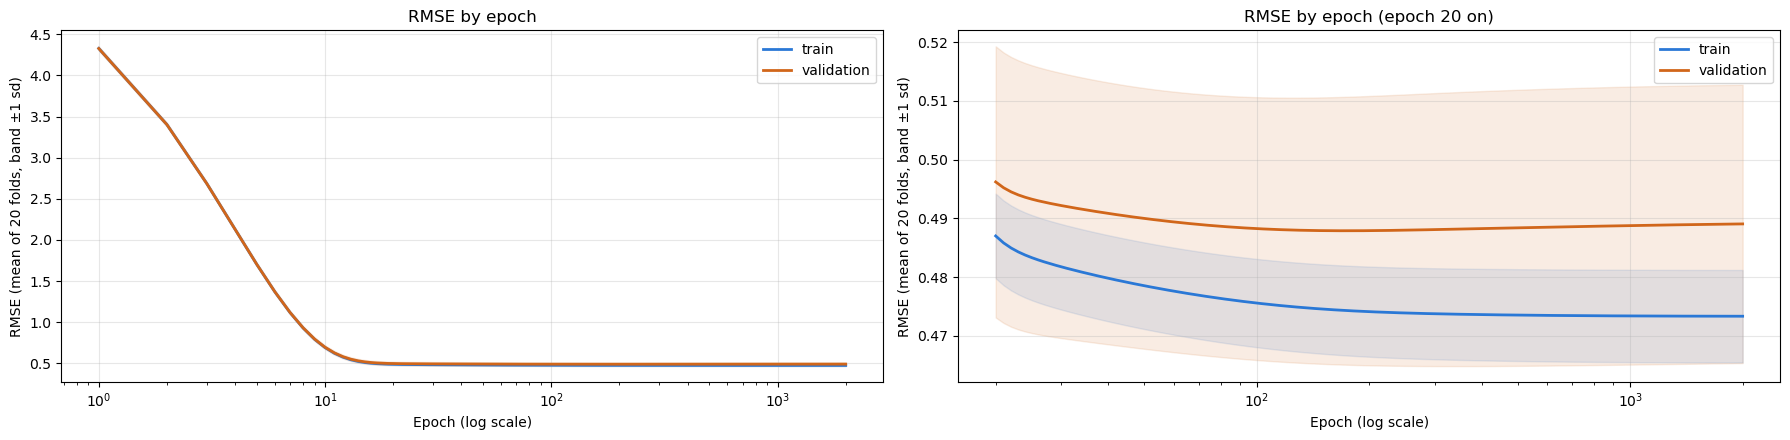

In [22]:
EPOCHS = 2000

curve = PIPELINES.loss_curve(build(FEATURE_CHOICE, SELECTED_MODEL, degree=DEGREE, scale=True), X=X_complete, y=y_complete, folds=FOLDS, epochs=EPOCHS)

by_epoch = curve.groupby(level="epoch").mean()
print(f"lowest validation rmse: {by_epoch['validation rmse'].min():.4f} at epoch {by_epoch['validation rmse'].idxmin()}")

display(by_epoch.loc[[1, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]].round(4))
PLOTTING.loss_curve(curve=curve, zoom_from=20, log_x=True);

## Save the Model

The fitted pipeline takes the 8 attributes as they are stored and builds its own feature columns, so it predicts on new rows with no preprocessing outside it.

In [23]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / "polynomial_regression.joblib"
joblib.dump(final_model, model_path)

reloaded = joblib.load(model_path)
print(f"saved: {model_path.name}")
print(f"reloaded predictions identical: {np.array_equal(reloaded.predict(X_complete), final_model.predict(X_complete))}")

saved: polynomial_regression.joblib
reloaded predictions identical: True


## Results

- **The selected model is degree 2 with Ridge at `alpha=0.001` and `eta0=0.001`,** at an rmse of 0.4889 over the 20 folds. The tiebreak that picks it over Elastic Net at 0.001 is far inside the noise (0.488905 against 0.489009).
- **It beats Q1D's linear model.** Against `Linear, Ridge SGD` (0.5164) its rmse is lower by 0.0275 with an SE of 0.0046 (Δ / SE -6.02), and r2 rises from 0.7893 to 0.8110.
- **The gain comes from the polynomial terms, not from the penalty.** It ties with plain SGD (0.4889) and with closed form at degree 2 (0.4894, a difference of 0.0005 against an SE of 0.0028). It is selected because the question asks for the best regularized setting.
- **Fit on all 1,374 complete rows, it behaves like the fold models.** It stops after 168 epochs with a training rmse of 0.4789, against 0.4770 across the folds. None of its 44 coefficients is exactly 0. The five largest belong to feature columns on their own, led by Healthy life expectancy's hinge (0.3373), and the largest polynomial term is that hinge squared (-0.1519).
- **The loss curve shows only slight overfitting with more training.** Almost all the learning is over by epoch 20 (0.4870 training, 0.4962 validation). Validation rmse is lowest at epoch 173 (0.4879), then drifts up to 0.4891 by epoch 2000 while training rmse keeps edging down (0.4741 at epoch 200, 0.4733 at epoch 2000). The fit on all the rows stopped at 168 epochs, next to that lowest point.

**Carry forward**

- **`polynomial_regression.joblib`,** the fitted pipeline, which reloads with identical predictions. Its cross validated rmse of 0.4889 is the estimate for rows it has not seen.

# Overfitting and Underfitting

Two views of overfitting and underfitting are already above: by degree with closed form (Degree) and by penalty strength (Regularization). This section adds SGD at the other degrees and the third view, by epoch.

## Other Degrees with SGD

The selected setting on the same feature columns at degree 1 and at degree 3, each stopped by its own rule. The degree was chosen with closed form, so these rows show how the degree behaves under SGD. They are not up for selection.

In [24]:
OTHER_DEGREES = {f"Degree {degree}, selected setting": degree for degree in [1, 3]}

epochs_by_degree = {}
for name, degree in {SELECTED_NAME: DEGREE, **OTHER_DEGREES}.items():
	pipeline = build(FEATURE_CHOICE, SELECTED_MODEL, degree=degree, scale=True)
	if name not in RESULTS:
		score(name, pipeline)
	# epochs run before SGD stops, fit once on all the complete rows
	fitted = PIPELINES.seed_pipeline(pipeline).fit(X_complete, y_complete)
	epochs_by_degree[name] = {"degree": degree, "columns": len(fitted["model"].coef_), "epochs run": fitted["model"].n_iter_}

display(pd.DataFrame.from_dict(epochs_by_degree, orient="index"))
display(fold_range([SELECTED_NAME, *OTHER_DEGREES]))
display(table([SELECTED_NAME, *OTHER_DEGREES], baseline=SELECTED_NAME))

,degree,columns,epochs run
"Ridge, alpha=0.001",2,44,168
"Degree 1, selected setting",1,8,69
"Degree 3, selected setting",3,164,111


,rmse mean,train rmse mean,lowest fold,median fold,highest fold,folds above Dummy
"Ridge, alpha=0.001",0.4889,0.4770,0.4421,0.4875,0.5297,0
"Degree 1, selected setting",0.5202,0.5166,0.4766,0.5183,0.5617,0
"Degree 3, selected setting",0.4836,0.4594,0.4452,0.4821,0.5417,0


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Ridge, alpha=0.001",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Degree 3, selected setting",0.4836,0.0243,0.4594,0.3649,0.0183,0.8149,0.0208,-0.0053,0.0061,-0.8629,0.1995,within noise,20
"Ridge, alpha=0.001",0.4889,0.0221,0.4770,0.3719,0.0157,0.8110,0.0179,0.0000,NaN,NaN,NaN,baseline,20
"Degree 1, selected setting",0.5202,0.0228,0.5166,0.3980,0.0161,0.7862,0.0181,0.0313,0.0055,5.6894,1.0000,worse,20


## Loss by Epoch at Degrees 1, 2 and 3

The same one epoch at a time loop as for the selected model, with the degree as the only change. Degree 2 is the curve from the Selected Model section.

,lowest validation rmse,at epoch,validation rmse at epoch 2000,train rmse at epoch 2000
Degree 1,0.5200,44,0.5201,0.5163
Degree 2 (selected),0.4879,173,0.4891,0.4733
Degree 3,0.4830,138,0.4913,0.4388


Degree 1                 Degree 2 (selected)                  \
      train rmse validation rmse          train rmse validation rmse   
epoch                                                                  
20        0.5193          0.5222              0.4870          0.4962   
50        0.5164          0.5200              0.4785          0.4900   
100       0.5163          0.5201              0.4756          0.4883   
200       0.5163          0.5201              0.4741          0.4879   
500       0.5163          0.5201              0.4735          0.4884   
1000      0.5163          0.5201              0.4734          0.4888   
2000      0.5163          0.5201              0.4733          0.4891   

        Degree 3                  
      train rmse validation rmse  
epoch                             
20        0.4738          0.4923  
50        0.4606          0.4843  
100       0.4547          0.4832  
200       0.4493          0.4832  
500       0.4439          0.4859  
1000      0.4410          0.4888  
2000      0.4388          0.4913

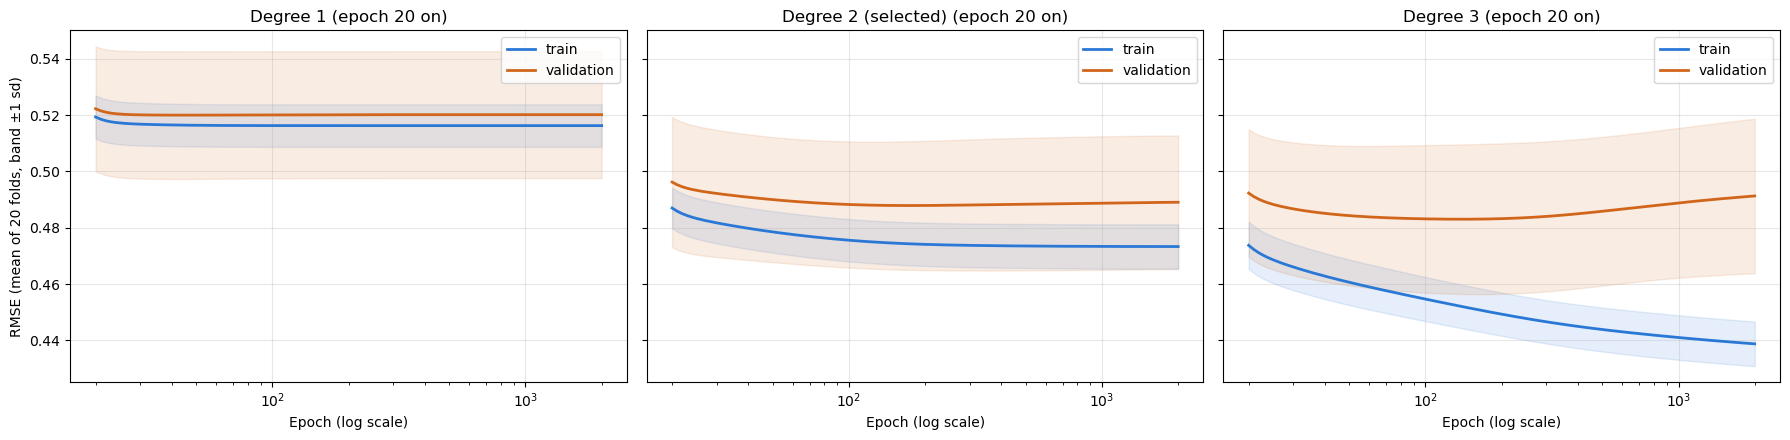

In [25]:
curves = {
	"Degree 1": PIPELINES.loss_curve(build(FEATURE_CHOICE, SELECTED_MODEL, degree=1, scale=True), X=X_complete, y=y_complete, folds=FOLDS, epochs=EPOCHS),
	"Degree 2 (selected)": curve,
	"Degree 3": PIPELINES.loss_curve(build(FEATURE_CHOICE, SELECTED_MODEL, degree=3, scale=True), X=X_complete, y=y_complete, folds=FOLDS, epochs=EPOCHS),
}

means = {name: one.groupby(level="epoch").mean() for name, one in curves.items()}

display(
	pd.DataFrame({
		name: {
			"lowest validation rmse": mean["validation rmse"].min(),
			"at epoch": mean["validation rmse"].idxmin(),
			f"validation rmse at epoch {EPOCHS}": mean["validation rmse"].iloc[-1],
			f"train rmse at epoch {EPOCHS}": mean["train rmse"].iloc[-1],
		}
		for name, mean in means.items()
	}).T.round(4).astype({"at epoch": int})
)
display(pd.concat(means, axis=1).loc[[20, 50, 100, 200, 500, 1000, 2000]].round(4))
PLOTTING.loss_curve(curve=curves, zoom_from=20, log_x=True);

## Results

- **The selected model does not underfit and overfits only slightly.** Across the folds its training and validation rmse are 0.4770 and 0.4889, and its loss curve ends just above its lowest validation rmse (0.4891 against 0.4879).
- **By degree, degree 1 underfits and degree 3 overfits.** With closed form, degree 1's training and validation rmse are close together and high (0.5121 and 0.5160), and degree 3's come apart (0.4253 and 0.6169).
- **By penalty, a stronger penalty moves the model toward underfitting.** Lasso at `alpha=0.1` raises training and validation rmse together, to 0.5398 and 0.5443.
- **By epoch, the three degrees part ways as training goes on.** Degree 1 is flat from epoch 100 on (0.5163 and 0.5201): more epochs cannot help a model that underfits. Degree 2 barely moves. Degree 3's training rmse falls for all 2000 epochs (0.4738 at epoch 20, 0.4388 at the end), while its validation rmse is lowest at epoch 138 (0.4830) and then climbs to 0.4913. The two validation lines meet at epoch 1000 (0.4888), and from there degree 3 is the worse one.
- **An early stop hides degree 3's overfitting.** Stopped by its own rule, after 111 epochs on all the complete rows, degree 3 scores 0.4836 with SGD, and even that is within noise of the selected model (lower by 0.0053 against an SE of 0.0061). Fit to the end with closed form it scores 0.6169. Degree 2's score does not depend on where training stops: 0.4889 with SGD and 0.4894 with closed form.

**Carry forward**

- **Degree 2 stays.** Degree 3 is no better even when it stops early, and worse the longer it trains.